## SLIDE 2

# Chuẩn bị

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

mat = pd.read_csv("student-mat.csv", sep=";")
por = pd.read_csv("student-por.csv", sep=";")
mat["Subject"] = "Math"
por["Subject"] = "Portuguese"
df = pd.concat([mat, por], ignore_index=True)

## Câu 1. Phân bố G3 có dạng gì?

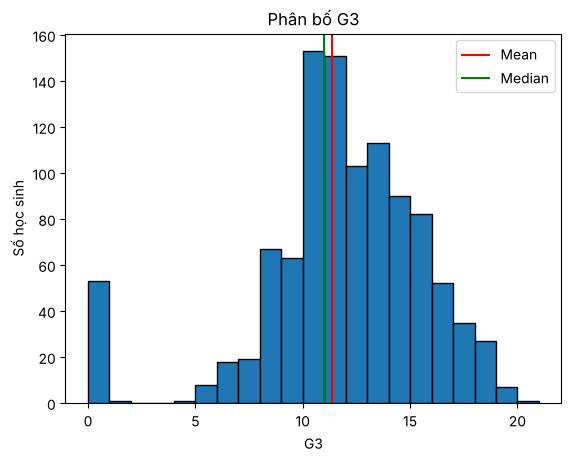

skew: -0.9859646596265084
skew khi bỏ điểm 0: 0.10562020040155115


In [2]:
df["G3"].plot.hist(bins=range(0, 22), edgecolor="black", label="_nolegend_")
plt.axvline(df.G3.mean(), color="red", label="Mean")
plt.axvline(df.G3.median(), color="green", label="Median")
plt.title("Phân bố G3")
plt.xlabel("G3")
plt.ylabel("Số học sinh")
plt.legend()
plt.show()

print("skew:", df.G3.skew())
print("skew khi bỏ điểm 0:", df[df.G3 > 0].G3.skew())

## Câu 2. Phân bố độ tuổi

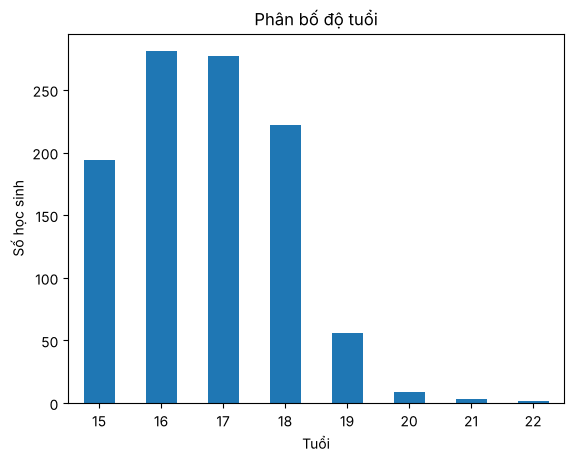

In [3]:
df["age"].value_counts().sort_index().plot.bar()
plt.xticks(rotation=0)
plt.title("Phân bố độ tuổi")
plt.xlabel("Tuổi")
plt.ylabel("Số học sinh")
plt.show()

## Câu 3. Phân bố thời gian học mỗi tuần (studytime)

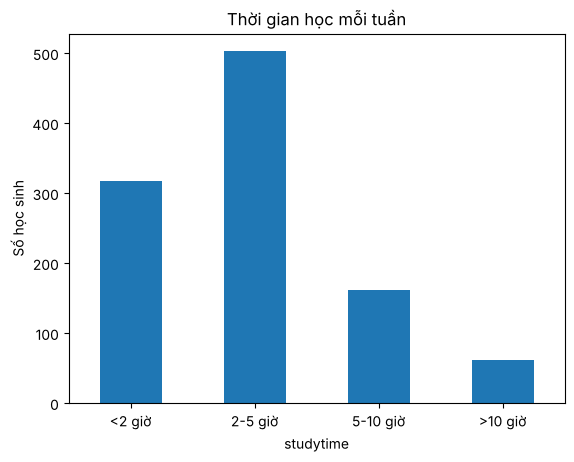

In [4]:
df["studytime"].value_counts().sort_index().plot.bar()
plt.xticks(range(4), ["<2 giờ", "2-5 giờ", "5-10 giờ", ">10 giờ"], rotation=0)
plt.title("Thời gian học mỗi tuần")
plt.ylabel("Số học sinh")
plt.show()

## Câu 4. So sánh phân bố G3 giữa nam và nữ (hue='sex')

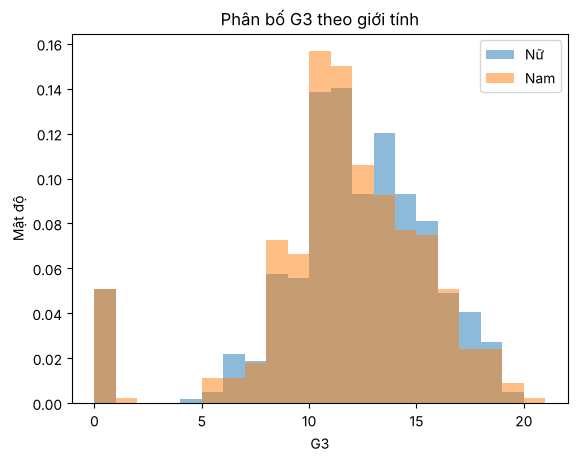

In [5]:
# pyplot không có hue nên vẽ từng giới tính rồi chồng lên nhau
df[df.sex == "F"]["G3"].plot.hist(bins=range(0, 22), alpha=0.5, density=True, label="Nữ")
df[df.sex == "M"]["G3"].plot.hist(bins=range(0, 22), alpha=0.5, density=True, label="Nam")
plt.title("Phân bố G3 theo giới tính")
plt.xlabel("G3")
plt.ylabel("Mật độ")
plt.legend()
plt.show()

## Câu 5. So sánh G3 giữa nam và nữ

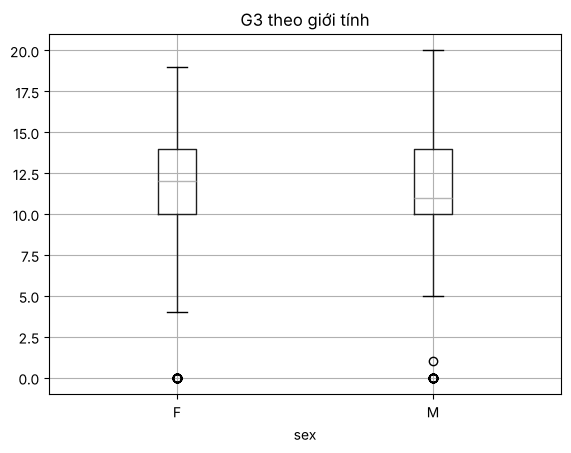

sex
F    11.448393
M    11.203091
Name: G3, dtype: float64
Subject     sex
Math        F       9.966346
            M      10.914439
Portuguese  F      12.253264
            M      11.406015
Name: G3, dtype: float64


In [6]:
df.boxplot(column="G3", by="sex")
plt.suptitle("")      # bỏ tiêu đề tự sinh của boxplot
plt.title("G3 theo giới tính")
plt.show()

print(df.groupby("sex")["G3"].mean())
print(df.groupby(["Subject", "sex"])["G3"].mean())

## Câu 6. So sánh G3 theo học vấn của cha mẹ (Medu / Fedu)

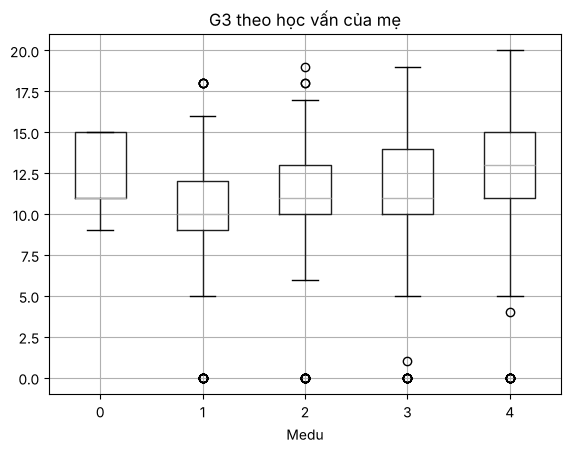

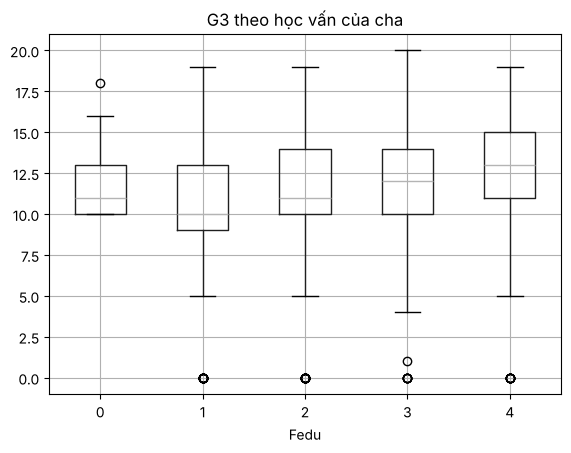

Medu
0    12.111111
1    10.178218
2    10.972318
3    11.247899
4    12.509804
Name: G3, dtype: float64
Fedu
0    12.333333
1    10.367188
2    11.243827
3    11.636364
4    12.254464
Name: G3, dtype: float64


In [7]:
df.boxplot(column="G3", by="Medu")
plt.suptitle("")
plt.title("G3 theo học vấn của mẹ")
plt.show()

df.boxplot(column="G3", by="Fedu")
plt.suptitle("")
plt.title("G3 theo học vấn của cha")
plt.show()

print(df.groupby("Medu")["G3"].mean())
print(df.groupby("Fedu")["G3"].mean())

## Câu 7. Ảnh hưởng của studytime tới phân bố G3

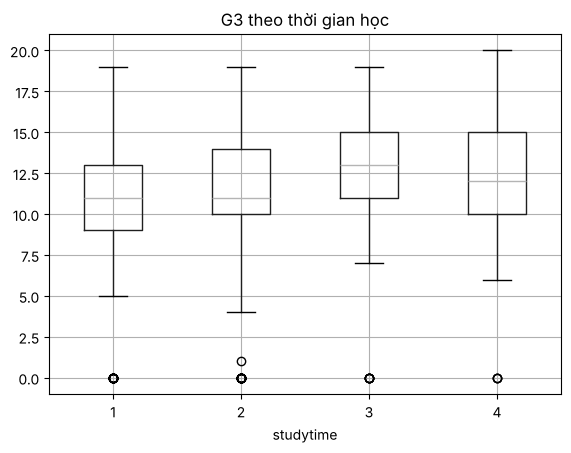

studytime
1    10.580442
2    11.335984
3    12.493827
4    12.274194
Name: G3, dtype: float64


In [8]:
df.boxplot(column="G3", by="studytime")
plt.suptitle("")
plt.title("G3 theo thời gian học")
plt.show()

print(df.groupby("studytime")["G3"].mean())

## Câu 8. So sánh G3 giữa học sinh có học thêm (paid) và không học thêm

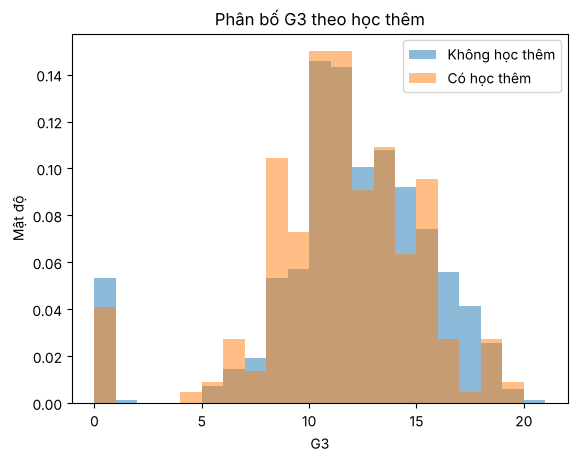

paid
no     11.440534
yes    10.972727
Name: G3, dtype: float64
Subject     paid
Math        no       9.985981
            yes     10.922652
Portuguese  no      11.950820
            yes     11.205128
Name: G3, dtype: float64


In [9]:
df[df.paid == "no"]["G3"].plot.hist(bins=range(0, 22), alpha=0.5, density=True, label="Không học thêm")
df[df.paid == "yes"]["G3"].plot.hist(bins=range(0, 22), alpha=0.5, density=True, label="Có học thêm")
plt.title("Phân bố G3 theo học thêm")
plt.xlabel("G3")
plt.ylabel("Mật độ")
plt.legend()
plt.show()

print(df.groupby("paid")["G3"].mean())
print(df.groupby(["Subject", "paid"])["G3"].mean())